# Generating Images of Surface Landmines: a Class-Conditional GAN Trained on SULAND

**Author:** Travis Carlson

**Dataset:** SULAND, the photos of the original SULAND release (Vivoli et al., 2024) with the refined SULAND_v2 labels (Lekhak et al., 2026), Hugging Face record [SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset](https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset), CC BY 4.0

This notebook trains a generative adversarial network (GAN) in PyTorch that generates 64 × 64 colour images of two kinds of surface landmine, the PFM-1 and the PMA-2, on request. It learns from real photos: crops cut around the labelled items in SULAND, a public set of video frames of mine surrogates lying in grass, leaves and gravel. The generated images are then judged against real ones.

**Generative task and approach:** image generation with a class-conditional GAN, one of the three approaches the brief allows (Task 1). The generator turns random numbers and a mine type into an image; the discriminator learns to tell real crops from generated ones; each improves against the other (Goodfellow et al., 2014). The layout follows the deep convolutional GAN, DCGAN (Radford et al., 2016), with the mine type given to both networks as an extra input, as in conditional GANs (Mirza & Osindero, 2014).

**Why generate mine images.** In the author's work in explosive ordnance disposal (EOD) and humanitarian mine action, generated images could serve as training images for a model that finds mines in drone or survey photos, for recognition training and awareness material, and for digital worlds in which drones, or drone operators, train. Two things decide whether they are fit for that: whether the item's shape is right (its colour matters less, since mines can be painted to camouflage), and whether a model trained on them works on real photos, especially at a site it has never seen. A picture that teaches people what a mine looks like has to be accurate, and these images are not drawn from engineering data, so they are judged here as training material, not as reference pictures.

**How the outputs are judged.** Section 7 looks at the samples of each type and the same random inputs through training; checks whether the samples copy training crops; trains a small classifier on generated mines and another on real ones and scores both on real test crops from Italy and from a site in the USA ("train on generated, test on real"; Esteban et al., 2017; Ravuri & Vinyals, 2019), then tests why the first one fails; generates images part-way between the two types; and records a blind review by the author, an EOD specialist, of real and generated crops mixed together.

**How the sections map to the brief.** Section 1 states the task and the data (Task 1); section 2 loads and inspects it (Task 2); section 3 prepares the crops (Task 2); sections 4 and 5 define and train the model (Task 3); sections 6 and 7 generate and evaluate samples (Task 4); section 8 is the summary (Task 5).

**Data handling.** The notebook stays at the level of mine types and counts and gives no technical detail of how the items work. The items in SULAND are surrogates, not live mines. Every generated image is labelled as generated. The 16.7 GB image archive is not needed to run the notebook: the crops it uses ship with it, and section 3.1 can rebuild them from the archive.

*References cited in this notebook:*
- Esteban, C., Hyland, S. L., & Rätsch, G. (2017). *Real-valued (medical) time series generation with recurrent conditional GANs* (arXiv:1706.02633). arXiv. https://arxiv.org/abs/1706.02633
- Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M., & Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*(11), 665–673. https://doi.org/10.1038/s42256-020-00257-z
- Goodfellow, I., Pouget-Abadie, J., Mirza, M., Xu, B., Warde-Farley, D., Ozair, S., Courville, A., & Bengio, Y. (2014). Generative adversarial nets. *Advances in Neural Information Processing Systems, 27*. https://proceedings.neurips.cc/paper_files/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html
- Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper_files/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html
- Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *Proceedings of the 32nd International Conference on Machine Learning, 37*, 448–456. https://proceedings.mlr.press/v37/ioffe15.html
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980
- Lekhak, S. (2026). *SULAND_v2 RGB surface landmine dataset* [Data set]. Hugging Face. https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset
- Lekhak, S., Pulakurthi, P. R., Joshi, L., Bhatta, R., & Ientilucci, E. J. (2026). *SULAND v2: A refined RGB dataset and deep learning object detection benchmark for UAV/UGV-based surface landmine detection under domain shift* (arXiv:2607.28996). arXiv. https://arxiv.org/abs/2607.28996
- Lopez-Paz, D., & Oquab, M. (2017). Revisiting classifier two-sample tests. *5th International Conference on Learning Representations*. https://openreview.net/forum?id=SJkXfE5xx
- Mirza, M., & Osindero, S. (2014). *Conditional generative adversarial nets* (arXiv:1411.1784). arXiv. https://arxiv.org/abs/1411.1784
- Odena, A., Dumoulin, V., & Olah, C. (2016). Deconvolution and checkerboard artifacts. *Distill, 1*(10), Article e3. https://doi.org/10.23915/distill.00003
- Radford, A., Metz, L., & Chintala, S. (2016). Unsupervised representation learning with deep convolutional generative adversarial networks. *4th International Conference on Learning Representations*. https://arxiv.org/abs/1511.06434
- Ravuri, S., & Vinyals, O. (2019). Classification accuracy score for conditional generative models. *Advances in Neural Information Processing Systems, 32*. https://proceedings.neurips.cc/paper_files/paper/2019/hash/fcf55a303b71b84d326fb1d06e332a26-Abstract.html
- Theis, L., van den Oord, A., & Bethge, M. (2016). A note on the evaluation of generative models. *4th International Conference on Learning Representations*. https://arxiv.org/abs/1511.01844
- Vivoli, E., Bertini, M., & Capineri, L. (2024). Deep learning-based real-time detection of surface landmines using optical imaging. *Remote Sensing, 16*(4), Article 677. https://doi.org/10.3390/rs16040677
- Whitney, C. D., & Norman, J. (2024). Real risks of fake data: Synthetic data, diversity-washing and consent circumvention. In *The 2024 ACM Conference on Fairness, Accountability, and Transparency* (pp. 1733–1744). Association for Computing Machinery. https://doi.org/10.1145/3630106.3659002

## 1. Problem and data

### 1.1 Setup

Libraries, file locations and checksums, fixed settings, and the chart style of the earlier projects. The workflow uses Python, NumPy, Pandas, Matplotlib, Seaborn, Pillow and PyTorch.

Every random step is seeded, PyTorch is told to use deterministic algorithms, and training runs on the CPU with a fixed number of threads, so rerunning the notebook on the same computer gives the same images and numbers. A different processor may round some sums in a different order, and over thousands of training steps such tiny differences grow, so on another computer the generated images and the scores will differ somewhat from those shown here.

In [1]:
import hashlib
import io
import json
import math
import struct
import time
import urllib.error
import urllib.request
import zipfile
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns
import PIL
from PIL import Image, ImageOps
import torch
import torch.nn as nn
import torch.nn.functional as F

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Files (the data folder sits next to this notebook)
DATA_DIR = Path("data")
MINE_ZIP = DATA_DIR / "mine_crops_64.zip"              # one 64 x 64 JPEG crop per kept box
BACKGROUND_ZIP = DATA_DIR / "background_crops_64.zip"  # one 64 x 64 JPEG square of ground per frame with a kept box
CROPS_CSV = DATA_DIR / "crops_manifest.csv"            # one row per crop: kind, split, type, frame, box, square
FRAMES_CSV = DATA_DIR / "frames.csv"                   # one row per frame of the four splits
BOXES_CSV = DATA_DIR / "boxes.csv"                     # one row per labelled box of the four splits
SAMPLE_DIR = DATA_DIR / "sample_photos"                # six frames, shrunk, to show the scenes
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Provenance of the data: the Hugging Face record at a fixed revision
RECORD_PAGE = "https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset"
ORIGINAL_RELEASE = "https://github.com/miccunifi/SULAND-Dataset"
READ_ON = "2026-10-21"
EXPECTED_SHA256 = {
    "mine_crops_64.zip": "2ddc12cd38dac2b2d621341171b3163d6e7b74d018854b09edabc7cceaa49adb",
    "background_crops_64.zip": "9cfe946399dfae19f4d7a9be82e9cdca93ab0d03c7fb933e9d7f4a36b2326f15",
    "crops_manifest.csv": "cac0c5593c0b37df522bc7ac3762bf1801d0edf11f5148760c37dbecfe69c286",
    "frames.csv": "6001c0f7f49ff9ef71db3547fb51791369d08100226f070430b8db6bf624ba5d",
    "boxes.csv": "5e82e9d8bbfaca2f76afe5f2f9b3aab5dc43a6d4a0207827f80aec72e365ad59",
}
REBUILD_CROPS = False       # True: read the frames again from the archive (about 5 GB) and rebuild the crops (section 3.1)

# Fixed settings
SEED = 0                    # one seed for every random step
THREADS = 2                 # CPU threads used by PyTorch, fixed so results do not depend on the computer's core count
TYPES = ["PFM-1", "PMA-2"]  # the two mine types, numbered 0 and 1
NZ = 100                    # random numbers the generator turns into an image
WIDTH = 32                  # channels in the networks' widest-resolution layer (the standard DCGAN uses 64)
BATCH = 64                  # crops per training step
EPOCHS = 40                 # passes over the training crops
LEARNING_RATE = 0.0002      # Adam's step size for both networks, as in DCGAN
BETA1 = 0.5                 # Adam's first-moment decay, as in DCGAN

torch.manual_seed(SEED)
torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)

# Chart style: light surface, quiet grid, neutrals for the data and one fixed colour per series
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
TYPE_COLOURS = {"PFM-1": "#2a78d6", "PMA-2": "#eb6834", "background": "#898781"}
SERIES = {"real": "#1baf7a", "generated": "#8a5cd1", "generator": "#2a78d6", "discriminator": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})


def save_fig(fig, name):
    """Save a figure to the figures folder at print resolution (JPEG for photos, PNG for charts) and return its path."""
    path = FIG_DIR / name
    options = {"pil_kwargs": {"quality": 90}} if path.suffix == ".jpg" else {}
    fig.savefig(path, dpi=200, bbox_inches="tight", **options)
    return path


def clean_axes(ax):
    """Hide ticks, grid and frame, for image panels."""
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)


for name, module in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns),
                     ("pillow", PIL), ("torch", torch)]:
    print(f"{name:<11} {module.__version__}")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\nPyTorch device available: {device}; training runs on the CPU with {THREADS} threads.")

numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
seaborn     0.13.2
pillow      13.0.0
torch       2.14.1+cpu

PyTorch device available: cpu; training runs on the CPU with 2 threads.


### 1.2 The dataset

SULAND (SUrface LANDmine) was released by Emanuele Vivoli, Marco Bertini and Lorenzo Capineri of the Media Integration and Communication Center (MICC) of the University of Florence, under a CC BY 4.0 licence, with a paper on detecting surface landmines in optical images (Vivoli et al., 2024). Its frames come from videos taken with a phone camera of surrogates of two surface mines, the PFM-1 and the PMA-2, laid in grass, leaves, soil and gravel: in Italy, for the training, validation and test splits, and on a campus in the USA, kept apart to test how detectors do at a site they have never seen.

SULAND_v2 (Lekhak et al., 2026, a preprint) keeps the original frames and the splits, which are made by video so that frames of one video stay in one split, and revises only the labels, after an audit that found missing and false boxes in the first release. Its Hugging Face record, also under CC BY 4.0, holds the frames in one archive of 16,674,324,895 bytes and the new labels in a second archive of 7,412,917 bytes (Lekhak, 2026). The record states that the dataset "is intended for academic research" and that performance on it "should not be interpreted as evidence of operational readiness for real-world humanitarian demining".

It meets the brief's dataset rules: images suited to image generation; public, with a documented source and licence; real photos rather than synthetic or AI-generated ones; and not used in an earlier project.

Three points shape the task:
- **Surrogates of two types.** The model can only learn what these two surrogates look like in these places. It cannot generate other mine types, and its images show surrogates, not live mines.
- **Two sites.** Italy's training split teaches the generator; Italy's test split and the US set are held out to judge it, the US set as a site the model has never seen.
- **Videos, not single photos.** Frames of one video show the same few items again and again, so the training crops hold far fewer distinct items than their count suggests (section 2.4).

## 2. Load and inspect

### 2.1 Data files and checksums

The notebook reads five files made from SULAND (section 3.1 shows how): the mine crops, the background crops, one row per crop, and the frames and labelled boxes of the four splits. Their SHA-256 checksums are compared with the values recorded when they were built, so anyone rerunning the notebook can confirm they use the same data.

In [2]:
def file_digest(path, algorithm="sha256"):
    """Return the hex digest of a file, reading it in 1 MB chunks."""
    digest = hashlib.new(algorithm)
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print(f"Dataset record: {RECORD_PAGE} (read on {READ_ON})")
print(f"Original release: {ORIGINAL_RELEASE}\n")
for path in [MINE_ZIP, BACKGROUND_ZIP, CROPS_CSV, FRAMES_CSV, BOXES_CSV]:
    digest = file_digest(path)
    verdict = "matches the recorded value" if digest == EXPECTED_SHA256[path.name] else "WARNING: differs from the recorded value"
    print(f"{path.name:<24} {path.stat().st_size:>12,} bytes   SHA-256 {digest[:12]}...  {verdict}")

Dataset record: https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset (read on 2026-10-21)
Original release: https://github.com/miccunifi/SULAND-Dataset



mine_crops_64.zip          40,594,542 bytes   SHA-256 2ddc12cd38da...  matches the recorded value


background_crops_64.zip    38,916,701 bytes   SHA-256 9cfe946399df...  matches the recorded value
crops_manifest.csv          2,623,003 bytes   SHA-256 cac0c5593c0b...  matches the recorded value
frames.csv                  2,860,564 bytes   SHA-256 6001c0f7f49f...  matches the recorded value
boxes.csv                   1,585,902 bytes   SHA-256 5e82e9d8bbfa...  matches the recorded value


### 2.2 The frames

One row per frame: its split, its video, its size in pixels, and how many labelled boxes it holds, all of them and those kept for cropping (section 2.3).

In [3]:
frames = pd.read_csv(FRAMES_CSV)
boxes = pd.read_csv(BOXES_CSV)
crops = pd.read_csv(CROPS_CSV)
SPLIT_ORDER = ["train", "val", "test", "usa"]
print(f"{len(frames):,} frames, {len(boxes):,} labelled boxes, {len(crops):,} crops\n")
print(frames.head(3).to_string(index=False), "\n")
print(frames.dtypes.to_string(), "\n")

by_split = frames.groupby("split").agg(frames=("frame", "size"), videos=("video", "nunique"),
                                       frames_with_boxes=("boxes", lambda b: int((b > 0).sum())),
                                       boxes=("boxes", "sum"), max_boxes=("boxes", "max")).loc[SPLIT_ORDER]
print(by_split.to_string(), "\n")
sizes = frames.apply(lambda r: f"{r.frame_w} x {r.frame_h}", axis=1).value_counts()
print("Frame sizes (width x height):", sizes.to_dict())
print("EXIF orientation tags of the frames cropped:", crops.drop_duplicates("frame").exif_orientation.value_counts().to_dict(),
      "(1 = upright as stored)")

33,771 frames, 12,427 labelled boxes, 20,308 crops



split                                                    frame  video  frame_w  frame_h  boxes  kept_boxes
train  SULAND_images/data-iid/train/images/ITA-v1/ITA-v1-0.jpg ITA-v1     1440     1920      1           1
train  SULAND_images/data-iid/train/images/ITA-v1/ITA-v1-1.jpg ITA-v1     1440     1920      1           1
train SULAND_images/data-iid/train/images/ITA-v1/ITA-v1-10.jpg ITA-v1     1440     1920      1           1 

split           str
frame           str
video           str
frame_w       int64
frame_h       int64
boxes         int64
kept_boxes    int64 

       frames  videos  frames_with_boxes  boxes  max_boxes
split                                                     
train   22756      34               6269   6711          2
val      2836       5                693    804          2
test     3743       6               1006   1056          2
usa      4436      10               3586   3856          4 



Frame sizes (width x height): {'1440 x 1920': 33771}
EXIF orientation tags of the frames cropped: {1: 9911} (1 = upright as stored)


Six frames, shrunk for display, with their labelled boxes: two of each type from Italy's training split, and one of each from the US set.

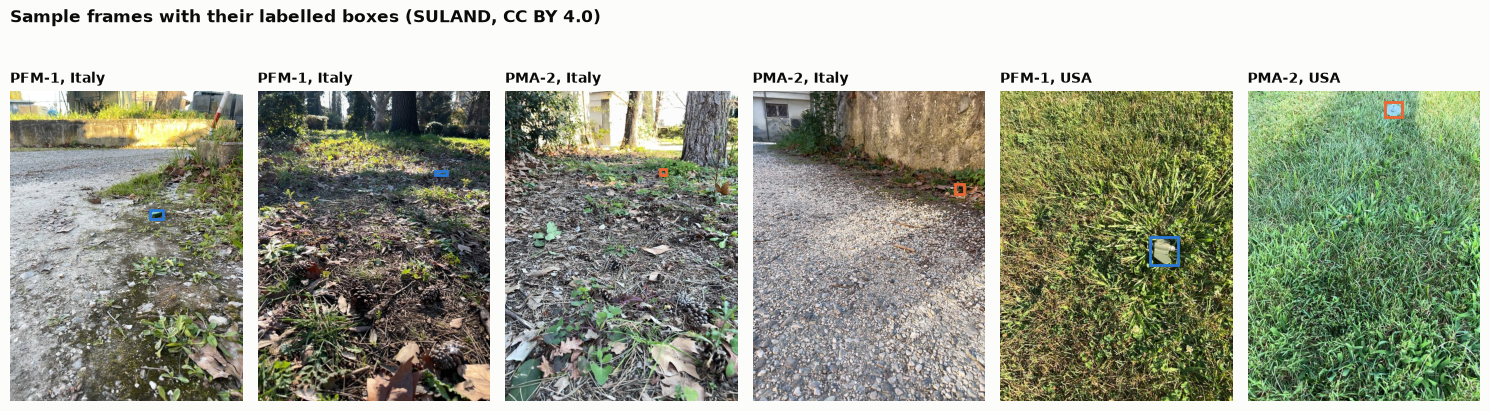

In [4]:
frame_of = {Path(f).name if Path(f).name.startswith(v) else f"{v}-{Path(f).name}": f
            for f, v in zip(frames.frame, frames.video)}
label_of = boxes.groupby("frame").label.first()
sample_files = sorted(SAMPLE_DIR.glob("*.jpg"), key=lambda p: (not p.name.startswith("ITA"), label_of[frame_of[p.name]], p.name))
fig, axes = plt.subplots(1, 6, figsize=(15, 4.6))
for ax, path in zip(axes, sample_files):
    image = Image.open(path)
    frame = frame_of[path.name]
    info = frames.set_index("frame").loc[frame]
    scale = image.width / info.frame_w
    ax.imshow(image)
    for box in boxes[boxes.frame == frame].itertuples():
        ax.add_patch(Rectangle((box.x * scale, box.y * scale), box.w * scale, box.h * scale,
                               fill=False, edgecolor=TYPE_COLOURS[box.label], linewidth=2))
        ax.set_title(f"{box.label}, {'Italy' if info.split != 'usa' else 'USA'}", fontsize=10)
    clean_axes(ax)
fig.suptitle("Sample frames with their labelled boxes (SULAND, CC BY 4.0)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "01_sample_photos.jpg")
plt.show()

### 2.3 The labels

Labelled boxes by type and split, and the boxes dropped before cropping: those that touch the edge of the frame, where the item is cut off, and those under 32 pixels on their longer side, too small to give a usable 64-pixel crop. The validation split is profiled here but not used: the model is judged on the test split and the US set.

In [5]:
boxes["side"] = boxes[["w", "h"]].max(axis=1)
table = boxes.pivot_table(index="split", columns="label", values="x", aggfunc="count", fill_value=0).loc[SPLIT_ORDER]
table["touch the edge"] = boxes[boxes.touches_edge].groupby("split").size().reindex(SPLIT_ORDER, fill_value=0)
table["under 32 px"] = boxes[~boxes.touches_edge & boxes.under_min_side].groupby("split").size().reindex(SPLIT_ORDER, fill_value=0)
kept_counts = boxes[boxes.kept].pivot_table(index="split", columns="label", values="x", aggfunc="count", fill_value=0)
table["kept PFM-1"], table["kept PMA-2"] = kept_counts["PFM-1"], kept_counts["PMA-2"]
print(table.to_string(), "\n")
used = boxes[boxes.split.isin(["train", "test", "usa"])]
print(f"Boxes kept in the three splits used: {used.kept.sum():,} of {len(used):,} ({used.kept.mean():.1%}).")
print("Mine crops in the manifest:", crops[crops.kind == "mine"].groupby(["split", "label"]).size().to_dict())

label  PFM-1  PMA-2  touch the edge  under 32 px  kept PFM-1  kept PMA-2
split                                                                   
train   3430   3281             476          345        2981        2909
val      431    373              74            7         383         340
test     539    517              72           51         468         465
usa     2454   1402             269           13        2287        1287 

Boxes kept in the three splits used: 10,397 of 11,623 (89.5%).
Mine crops in the manifest: {('test', 'PFM-1'): 468, ('test', 'PMA-2'): 465, ('train', 'PFM-1'): 2981, ('train', 'PMA-2'): 2909, ('usa', 'PFM-1'): 2287, ('usa', 'PMA-2'): 1287}


### 2.4 The crops

All crops are read into arrays of 8-bit RGB pixels, in the order of the crop manifest: the mine crops, which the generator learns from and which the evaluation compares with, and the background crops, squares of the scene cut from the same frames away from every box (mostly ground, sometimes a wall or a shadow), which the classifier check in section 7.2 needs.

In [6]:
def load_crops(zip_path, names):
    """Read JPEG crops from a zip file into an array of shape (crops, height, width, 3), 8-bit RGB."""
    with zipfile.ZipFile(zip_path) as archive:
        return np.stack([np.asarray(Image.open(io.BytesIO(archive.read(name))).convert("RGB")) for name in names])


mines = crops[crops.kind == "mine"].reset_index(drop=True)
grounds = crops[crops.kind == "background"].reset_index(drop=True)
mine_images = load_crops(MINE_ZIP, mines.file)
ground_images = load_crops(BACKGROUND_ZIP, grounds.file)
print(f"Mine crops:       {mine_images.shape} {mine_images.dtype}, values {mine_images.min()} to {mine_images.max()}")
print(f"Background crops: {ground_images.shape} {ground_images.dtype}")
print(pd.concat([mines, grounds]).groupby(["split", "label"]).size().unstack(fill_value=0).loc[["train", "test", "usa"]].to_string())

Mine crops:       (10397, 64, 64, 3) uint8, values 0 to 255
Background crops: (9911, 64, 64, 3) uint8
label  PFM-1  PMA-2  background
split                          
train   2981   2909        5675
test     468    465         902
usa     2287   1287        3334


Eight crops of each type, and of ground, from Italy's training split and from the US set.

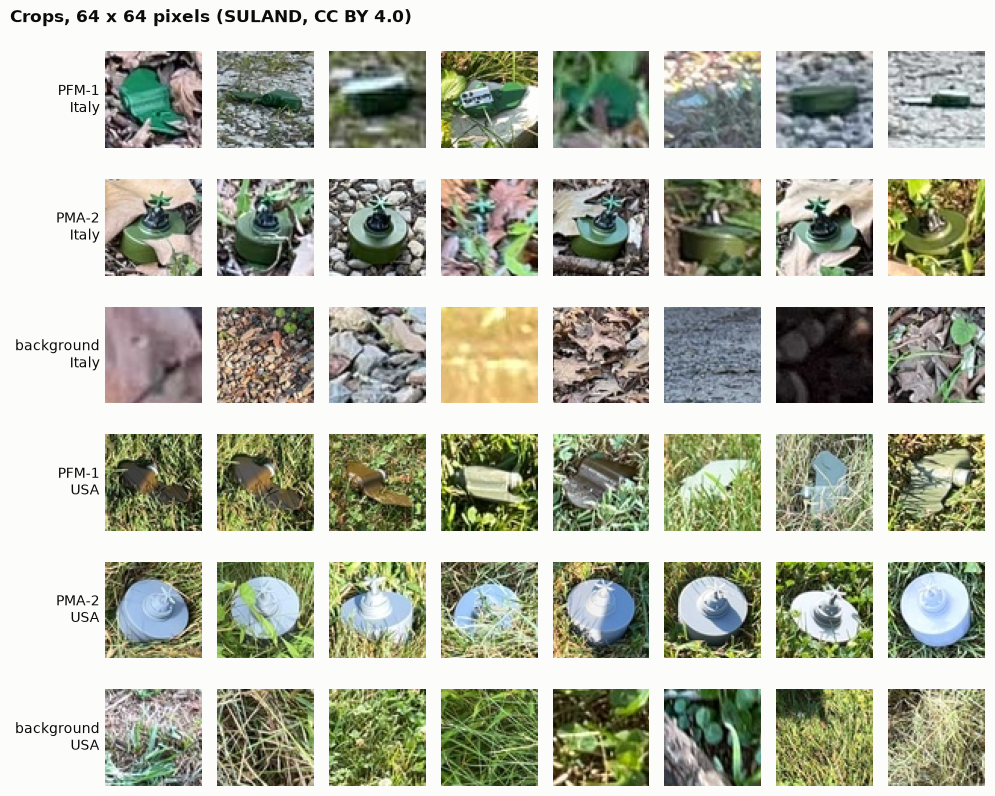

In [7]:
rng = np.random.default_rng(SEED)
panels = [("Italy", "train", "PFM-1"), ("Italy", "train", "PMA-2"), ("Italy", "train", "background"),
          ("USA", "usa", "PFM-1"), ("USA", "usa", "PMA-2"), ("USA", "usa", "background")]
fig, axes = plt.subplots(len(panels), 8, figsize=(10, 8.2))
for row, (site, split, label) in enumerate(panels):
    table, images = (grounds, ground_images) if label == "background" else (mines, mine_images)
    pool = np.flatnonzero(((table.split == split) & (table.label == label)).to_numpy())
    for col, index in enumerate(rng.choice(pool, 8, replace=False)):
        axes[row, col].imshow(images[index])
        clean_axes(axes[row, col])
    axes[row, 0].set_ylabel(f"{label}\n{site}", rotation=0, ha="right", va="center", fontsize=10, color=INK)
fig.suptitle("Crops, 64 x 64 pixels (SULAND, CC BY 4.0)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_sample_crops.jpg")
plt.show()

### 2.5 Data quality

Four checks on the boxes and crops:
- **Item size.** How large the items are in their frames, on the longer side of the box. Small items give blurry crops once enlarged to 64 pixels.
- **Repetition within videos.** How many training crops each video gives. Frames of one video show the same items from slightly different points of view, so a large share of crops from a few videos means few distinct items.
- **Near-duplicate crops.** Each crop's 64-bit difference hash records whether each pixel of a 9 × 8 grey thumbnail is brighter than its neighbour, so near-identical crops get hashes that differ in few bits. Pairs within 4 bits are counted among the training crops, and between the test or US crops and the training crops; the second count should be near zero, since the splits are made by video and site.
- **Colour by site.** The average colour of the centre of the mine crops, by site and type.

In [8]:
print("Longer side of the kept boxes, in pixels of the 1440 x 1920 frame:")
kept_boxes = boxes[boxes.kept & boxes.split.isin(["train", "test", "usa"])]
print(kept_boxes.groupby(["split", "label"]).side.describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]].round(0).to_string(), "\n")

per_video = mines[mines.split == "train"].groupby("video").size().sort_values(ascending=False)
print(f"Training crops by video: {per_video.size} videos; median {per_video.median():.0f} crops per video, "
      f"largest {per_video.iloc[0]}; the 5 largest videos give {per_video.head(5).sum() / per_video.sum():.0%} of the crops.\n")


def dhash(images):
    """64-bit difference hash of each image: is each pixel of a 9 x 8 grey thumbnail brighter than its right-hand neighbour?"""
    grey = np.stack([np.asarray(Image.fromarray(im).convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16) for im in images])
    bits = (grey[:, :, 1:] > grey[:, :, :-1]).reshape(len(images), 64)
    return np.packbits(bits, axis=1).view(">u8").ravel().astype(np.uint64)


hashes = dhash(mine_images)
split_of = mines.split.to_numpy()
train_hashes = hashes[split_of == "train"]
near_train = np.zeros(len(train_hashes), dtype=bool)
for start in range(0, len(train_hashes), 1000):
    within = np.bitwise_count(train_hashes[start:start + 1000, None] ^ train_hashes[None, :])
    within[np.arange(len(within)), np.arange(start, start + len(within))] = 64   # not a crop and itself
    near_train[start:start + 1000] = (within <= 4).any(axis=1)
print(f"Training crops with a near-duplicate among the other training crops: {near_train.sum():,} of {len(train_hashes):,} ({near_train.mean():.0%})")
for split in ["test", "usa"]:
    across = np.bitwise_count(hashes[split_of == split][:, None] ^ train_hashes[None, :])
    print(f"{split.upper() if split == 'usa' else split.capitalize()} crops with a near-duplicate among the training crops: "
          f"{(across <= 4).any(axis=1).sum()} of {(split_of == split).sum():,}")

centre = mine_images[:, 16:48, 16:48].reshape(len(mine_images), -1, 3).mean(axis=1)
colour = pd.DataFrame(centre, columns=["red", "green", "blue"]).assign(site=np.where(split_of == "usa", "USA", "Italy"), type=mines.label)
print("\nAverage colour of the centre 32 x 32 pixels of the mine crops (0 to 255):")
print(colour.groupby(["site", "type"])[["red", "green", "blue"]].mean().round(0).to_string())

Longer side of the kept boxes, in pixels of the 1440 x 1920 frame:
              count    10%    50%    90%
split label                             
test  PFM-1   468.0   47.0  122.0  243.0
      PMA-2   465.0   40.0   99.0  185.0
train PFM-1  2981.0   47.0  112.0  258.0
      PMA-2  2909.0   47.0  100.0  189.0
usa   PFM-1  2287.0  101.0  231.0  345.0
      PMA-2  1287.0   65.0  170.0  257.0 

Training crops by video: 34 videos; median 173 crops per video, largest 352; the 5 largest videos give 27% of the crops.



Training crops with a near-duplicate among the other training crops: 1,425 of 5,890 (24%)
Test crops with a near-duplicate among the training crops: 0 of 933
USA crops with a near-duplicate among the training crops: 0 of 3,574



Average colour of the centre 32 x 32 pixels of the mine crops (0 to 255):
               red  green   blue
site  type                      
Italy PFM-1   97.0  130.0  109.0
      PMA-2  103.0  115.0   94.0
USA   PFM-1  138.0  155.0  134.0
      PMA-2  168.0  189.0  193.0


**What the checks show.** All 33,771 frames are 1440 × 1920 pixels, and the frames cropped are stored upright (EXIF orientation 1), so the boxes are used as given. The items are small in their frames: in Italy the median kept box is 99 to 122 pixels on its longer side and a tenth are under 40 to 47, so many crops are enlarged from few pixels and look soft; at the US site the items fill more of the frame (medians 170 and 231 pixels). The 34 training videos give 173 crops each at the median and 352 at most, and the five largest give 27% of the training crops. 24% of the training crops have a near-duplicate among the other training crops, while no test or US crop has one among the training crops, as expected of splits made by video and site; the copy check in section 7.1 therefore compares the generated images with real test crops, which come from other videos. The surrogates were painted differently at the two sites: the centres of the Italian crops are green on average (red 97 to 103, green 115 to 130, blue 94 to 109 on a 0–255 scale), the US ones lighter and greyer, above all the PMA-2 (168, 189, 193). A model trained on the Italian crops has seen neither these colours nor this ground.

## 3. Prepare the crops

### 3.1 How the crops were made

Each kept box is cut out as a square, widened by 15% of the box's longer side on each side to keep some of the ground around the item, moved inside the frame where it would run past an edge, and resized to 64 × 64 pixels; a box that touches the frame's edge or measures under 32 pixels is dropped (section 2.3). For the classifier check, each frame with a kept box also gives one square of the scene, the same size as one of its crops, at a random position clear of every box. The size of 64 pixels was set by a timing test: about half a minute per pass over the training crops for this GAN on a 2-core processor.

The frames are read from the SULAND archive on Hugging Face at a fixed revision. The archive stores the photos uncompressed, so each frame can be read on its own with an HTTP range request, without downloading all 16.7 GB; each frame is checked against the CRC-32 in the archive's directory. The crops are saved as high-quality JPEGs in two zip files with fixed timestamps, so that rebuilding gives byte-identical files.

The code below made the shipped files. It runs only when `REBUILD_CROPS` is set to `True` in section 1.1 (about 5 GB is read, which took 6 minutes on the 2-core workspace), or when a local copy of the archive sits in the data folder; otherwise the notebook goes on with the shipped crops.

In [9]:
REPO = "SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset"
REVISION = "36f054cd593804decac44666a7c721b2106b7cff"
IMAGES_URL = f"https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/SULAND_images.zip"
LABELS_URL = f"https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/Annotation_files_for_SULAND_v2.zip"
CROP_SIZE = 64
MARGIN = 0.15
MIN_SIDE = 32
JPEG_QUALITY = 95
ZIP_TIME = (2026, 1, 1, 0, 0, 0)
# our split name: (folder in the archive, split folder, COCO file stem); the validation split is profiled, not cropped
SPLITS = {"train": ("data-iid", "train", "train"), "val": ("data-iid", "val", "val"),
          "test": ("data-iid", "test", "test"), "usa": ("data-ood", "val", "val")}
USED = ("train", "test", "usa")
CLASS_NAMES = {0: "PFM-1", 1: "PMA-2"}


def load_tables(labels_zip):
    """Every frame and every v2 box of the four splits, with each frame's path in the image archive."""
    frames, rows = [], []
    with zipfile.ZipFile(labels_zip) as z:
        for split, (folder, sub, stem) in SPLITS.items():
            coco = json.loads(z.read(f"SULAND_v2/{folder}/annotations/instances_{stem}.json"))
            images = {im["id"]: im for im in coco["images"]}
            for im in coco["images"]:
                frames.append({"split": split, "frame": f"SULAND_images/{folder}/{sub}/{im['file_name']}",
                               "video": im["file_name"].split("/")[1], "frame_w": im["width"], "frame_h": im["height"]})
            for a in coco["annotations"]:
                im = images[a["image_id"]]
                x, y, w, h = a["bbox"]
                rows.append({"split": split, "frame": f"SULAND_images/{folder}/{sub}/{im['file_name']}",
                             "video": im["file_name"].split("/")[1], "label": int(a["category_id"]),
                             "x": x, "y": y, "w": w, "h": h, "frame_w": im["width"], "frame_h": im["height"]})
    boxes = pd.DataFrame(rows)
    side = boxes[["w", "h"]].max(axis=1)
    touches = ((boxes.x < 1) | (boxes.y < 1) | (boxes.x + boxes.w > boxes.frame_w - 1)
               | (boxes.y + boxes.h > boxes.frame_h - 1))
    boxes["touches_edge"] = touches
    boxes["under_min_side"] = side < MIN_SIDE
    boxes["kept"] = ~touches & (side >= MIN_SIDE)
    return pd.DataFrame(frames), boxes


def load_boxes(labels_zip):
    """The boxes of the splits that are cropped."""
    boxes = load_tables(labels_zip)[1]
    return boxes[boxes.split.isin(USED)].reset_index(drop=True)


def encode_jpeg(array):
    buffer = io.BytesIO()
    Image.fromarray(array).save(buffer, format="JPEG", quality=JPEG_QUALITY)
    return buffer.getvalue()


def write_crop_zip(path, names, arrays):
    """A zip of JPEG crops, stored, with fixed dates, so the same crops always give the same file."""
    with zipfile.ZipFile(path, "w", compression=zipfile.ZIP_STORED) as z:
        for name, array in zip(names, arrays):
            info = zipfile.ZipInfo(name, date_time=ZIP_TIME)
            info.external_attr = 0o644 << 16
            z.writestr(info, encode_jpeg(array))


def read_crop_zip(path, names):
    """The crops in the order of `names`, as a uint8 array of shape (n, 64, 64, 3)."""
    with zipfile.ZipFile(path) as z:
        return np.stack([np.asarray(Image.open(io.BytesIO(z.read(n))).convert("RGB")) for n in names])


def crop_square(x, y, w, h, frame_w, frame_h):
    """Square around a box, 15% of its longer side wider on each side, moved inside the frame."""
    side = int(round(min(max(w, h) * (1 + 2 * MARGIN), frame_w, frame_h)))
    x0 = int(round(min(max(x + w / 2 - side / 2, 0), frame_w - side)))
    y0 = int(round(min(max(y + h / 2 - side / 2, 0), frame_h - side)))
    return x0, y0, side


def background_square(frame, frame_boxes, frame_w, frame_h, tries=200):
    """A square the size of one kept box's crop, at a random position clear of every box (with a margin)."""
    rng = np.random.default_rng(zlib.crc32(frame.encode()))
    kept = frame_boxes[frame_boxes.kept]
    pick = kept.iloc[int(rng.integers(len(kept)))]
    side = crop_square(pick.x, pick.y, pick.w, pick.h, frame_w, frame_h)[2]
    zones = [(b.x - MARGIN * max(b.w, b.h), b.y - MARGIN * max(b.w, b.h),
              b.x + b.w + MARGIN * max(b.w, b.h), b.y + b.h + MARGIN * max(b.w, b.h)) for b in frame_boxes.itertuples()]
    for _ in range(tries):
        x0, y0 = int(rng.integers(0, frame_w - side + 1)), int(rng.integers(0, frame_h - side + 1))
        if all(x0 + side <= zx0 or x0 >= zx1 or y0 + side <= zy0 or y0 >= zy1 for zx0, zy0, zx1, zy1 in zones):
            return x0, y0, side
    return None


class Archive:
    """Members of SULAND_images.zip, from a local copy or from a URL by HTTP range requests."""

    def __init__(self, source):
        self.source = str(source)
        self.remote = self.source.startswith("http")
        self.url = self._resolve() if self.remote else None
        self.size = self._size()
        self.bytes_read = 0
        with zipfile.ZipFile(_RangeFile(self)) as z:
            self.members = {i.filename: i for i in z.infolist()}

    def _resolve(self):
        """Follow the redirect once, to the file's signed address, so later reads skip it."""
        with urllib.request.urlopen(urllib.request.Request(self.source, headers={"Range": "bytes=0-0"}), timeout=60) as r:
            return r.geturl()

    def _size(self):
        if not self.remote:
            return Path(self.source).stat().st_size
        with urllib.request.urlopen(urllib.request.Request(self.url, headers={"Range": "bytes=0-0"}), timeout=60) as r:
            return int(r.headers["Content-Range"].split("/")[-1])

    def read_range(self, start, length):
        if not self.remote:
            with open(self.source, "rb") as f:
                f.seek(start)
                return f.read(length)
        for attempt in range(8):
            try:
                req = urllib.request.Request(self.url, headers={"Range": f"bytes={start}-{start + length - 1}"})
                with urllib.request.urlopen(req, timeout=120) as r:
                    data = r.read()
                self.bytes_read += len(data)
                return data
            except urllib.error.HTTPError as e:
                if e.code in (401, 403, 410):          # the signed address expired: resolve it again
                    self.url = self._resolve()
                if attempt == 7:
                    raise
            except OSError:
                if attempt == 7:
                    raise
            time.sleep(1 + attempt)

    def read(self, name):
        """The bytes of one stored member, checked against its CRC-32."""
        info = self.members[name]
        assert info.compress_type == zipfile.ZIP_STORED
        head = 30 + len(info.orig_filename.encode()) + 256
        buf = self.read_range(info.header_offset, head + info.compress_size)
        assert buf[:4] == b"PK\x03\x04", name
        n, m = struct.unpack("<HH", buf[26:30])
        start = 30 + n + m
        if start + info.compress_size > len(buf):
            buf += self.read_range(info.header_offset + len(buf), start + info.compress_size - len(buf))
        data = buf[start:start + info.compress_size]
        assert zlib.crc32(data) & 0xFFFFFFFF == info.CRC, f"CRC mismatch: {name}"
        return data


class _RangeFile(io.RawIOBase):
    """Just enough of a file for zipfile to read the archive's directory through Archive.read_range."""

    def __init__(self, archive):
        self.archive, self.pos = archive, 0

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=io.SEEK_SET):
        self.pos = {io.SEEK_SET: offset, io.SEEK_CUR: self.pos + offset, io.SEEK_END: self.archive.size + offset}[whence]
        return self.pos

    def read(self, n=-1):
        n = self.archive.size - self.pos if n is None or n < 0 else min(n, self.archive.size - self.pos)
        data = self.archive.read_range(self.pos, n) if n > 0 else b""
        self.pos += len(data)
        return data

    def readinto(self, b):
        data = self.read(len(b))
        b[:len(data)] = data
        return len(data)


def open_frame(data):
    """A frame as RGB, turned upright as its EXIF tag says, and that tag."""
    im = Image.open(io.BytesIO(data))
    orientation = im.getexif().get(274, 1)
    return ImageOps.exif_transpose(im).convert("RGB"), orientation


def cut(im, x0, y0, side):
    return np.asarray(im.crop((x0, y0, x0 + side, y0 + side)).resize((CROP_SIZE, CROP_SIZE), Image.LANCZOS), dtype=np.uint8)


def build_crops(boxes, archive, workers=16, keep_frames=()):
    """Mine and background crops for every frame with a kept box, with one manifest row per crop.

    keep_frames: frames to return whole as well (for the notebook's sample figure).
    """
    frames = boxes[boxes.kept].frame.unique()
    by_frame = {f: g for f, g in boxes[boxes.frame.isin(frames)].groupby("frame")}

    def one(frame):
        g = by_frame[frame]
        im, orientation = open_frame(archive.read(frame))
        fw, fh = int(g.frame_w.iloc[0]), int(g.frame_h.iloc[0])
        assert im.size == (fw, fh), (frame, im.size)
        out = []
        for b in g[g.kept].itertuples():
            x0, y0, side = crop_square(b.x, b.y, b.w, b.h, fw, fh)
            out.append((dict(kind="mine", split=b.split, frame=frame, video=b.video, label=CLASS_NAMES[b.label],
                             box_x=b.x, box_y=b.y, box_w=b.w, box_h=b.h, x0=x0, y0=y0, side=side,
                             exif_orientation=orientation), cut(im, x0, y0, side)))
        bg = background_square(frame, g, fw, fh)
        if bg is not None:
            first = g.iloc[0]
            out.append((dict(kind="background", split=first.split, frame=frame, video=first.video, label="background",
                             box_x=np.nan, box_y=np.nan, box_w=np.nan, box_h=np.nan, x0=bg[0], y0=bg[1], side=bg[2],
                             exif_orientation=orientation), cut(im, *bg)))
        whole = im.copy() if frame in keep_frames else None
        return out, whole

    rows, arrays, wholes = [], [], {}
    start = time.time()
    with ThreadPoolExecutor(workers) as pool:
        for i, (out, whole) in enumerate(pool.map(one, sorted(frames)), 1):
            for row, arr in out:
                rows.append(row)
                arrays.append(arr)
            if whole is not None:
                wholes[out[0][0]["frame"]] = whole
            if i % 500 == 0 or i == len(frames):
                print(f"{i:,} of {len(frames):,} frames, {archive.bytes_read / 1e9:.2f} GB read, {time.time() - start:.0f} s", flush=True)
    manifest = pd.DataFrame(rows)
    manifest.insert(0, "crop_id", range(len(manifest)))
    return manifest, np.stack(arrays), wholes


LOCAL_IMAGES = DATA_DIR / "SULAND_images.zip"
if REBUILD_CROPS or LOCAL_IMAGES.exists():
    rebuilt = Path("rebuilt_crops")
    rebuilt.mkdir(exist_ok=True)
    labels_zip = DATA_DIR / "Annotation_files_for_SULAND_v2.zip"
    if not labels_zip.exists():
        urllib.request.urlretrieve(LABELS_URL, labels_zip)
    started = time.perf_counter()
    archive = Archive(LOCAL_IMAGES if LOCAL_IMAGES.exists() else IMAGES_URL)
    rebuilt_manifest, rebuilt_arrays, _ = build_crops(load_boxes(labels_zip), archive)
    rebuilt_manifest["file"] = [f"{i:05d}.jpg" for i in rebuilt_manifest.crop_id]
    for kind, name in [("mine", "mine_crops_64.zip"), ("background", "background_crops_64.zip")]:
        part = rebuilt_manifest[rebuilt_manifest.kind == kind]
        write_crop_zip(rebuilt / name, part.file, rebuilt_arrays[part.index.values])
        same = file_digest(rebuilt / name) == EXPECTED_SHA256[name]
        print(f"{name:<24} {'identical to the shipped file' if same else 'WARNING: differs from the shipped file'}")
    print(f"Rebuilt {len(rebuilt_manifest):,} crops in {time.perf_counter() - started:.0f} s")
else:
    print("REBUILD_CROPS is False and no local copy of the archive is present, so the shipped crops are used.")

REBUILD_CROPS is False and no local copy of the archive is present, so the shipped crops are used.


### 3.2 Model inputs

The generator learns from the 5,890 mine crops of Italy's training split. Pixel values are scaled from 0–255 to −1 to 1, the range of the generator's final tanh layer. Each crop's type is given to both networks as a one-hot vector: (1, 0) for a PFM-1 and (0, 1) for a PMA-2. During training, each crop is flipped left to right at random half the time, since an item seen from the other side is still an item of its type; the crops are held channel-last in memory, the order of the image files, which PyTorch's CPU convolutions process faster.

The test crops from Italy and the US crops are not seen in training; section 7 uses them, with the background crops, to judge the generated images.

In [10]:
def to_unit_range(images):
    """8-bit RGB images (n, 64, 64, 3) to a float tensor (n, 3, 64, 64) in [-1, 1], channel-last in memory."""
    tensor = torch.from_numpy(np.ascontiguousarray(images)).permute(0, 3, 1, 2).float().div(127.5).sub(1)
    return tensor.contiguous(memory_format=torch.channels_last)


def to_8bit(tensor):
    """The inverse of to_unit_range: a float tensor in [-1, 1] back to 8-bit RGB images (n, 64, 64, 3)."""
    return ((tensor.detach().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).permute(0, 2, 3, 1).numpy()


train_rows = np.flatnonzero((mines.split == "train").to_numpy())
x_train = to_unit_range(mine_images[train_rows])
y_train = torch.from_numpy(np.array(mines.label.iloc[train_rows].map({t: i for i, t in enumerate(TYPES)})))
print(f"Training inputs: {tuple(x_train.shape)}, values {x_train.min():.2f} to {x_train.max():.2f}")
print("Training crops by type:", {t: int((y_train == i).sum()) for i, t in enumerate(TYPES)})
print(f"Steps per pass over the training crops: {len(x_train) // BATCH} batches of {BATCH} (the last {len(x_train) % BATCH} crops of each shuffled pass are left out)")

Training inputs: (5890, 3, 64, 64), values -1.00 to 1.00
Training crops by type: {'PFM-1': 2981, 'PMA-2': 2909}
Steps per pass over the training crops: 92 batches of 64 (the last 2 crops of each shuffled pass are left out)
